<a href="https://colab.research.google.com/github/marcus62-wq/Crosstalk-Analysis-of-Multiconductor-Transmission-Lines-over-Metallic-and-Composite-Ground-Planes/blob/main/Redu%C3%A7%C3%A3o_de_modelo_MTL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


Equivalent parameters:
h_eq  = 9.16 cm
r_eq  = 3.13 cm
Rn_eq = 31.39 ohm
Rf_eq = 31.39 ohm
L_eq  = 3.538e-07 H/m

Error metrics:
                            MAE (V)  RMSE (V)  MAX error (V)
Near-end: Reduced vs Full  0.000065  0.000131       0.000439
Far-end: Reduced vs Full   0.000065  0.000136       0.000493


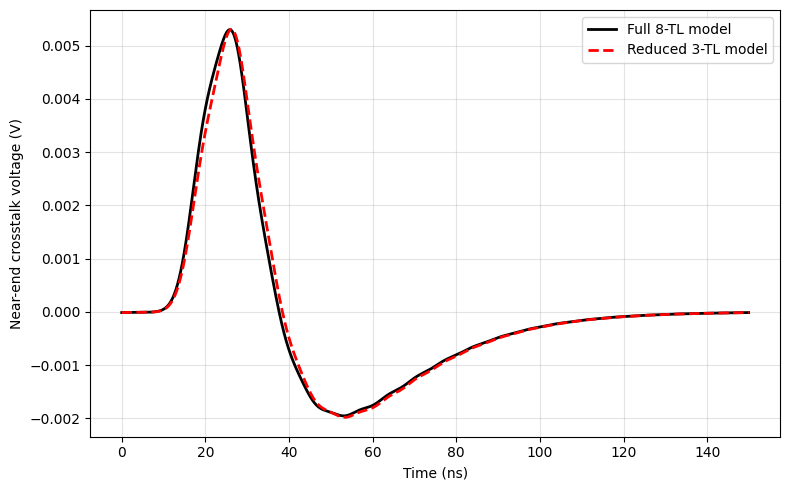

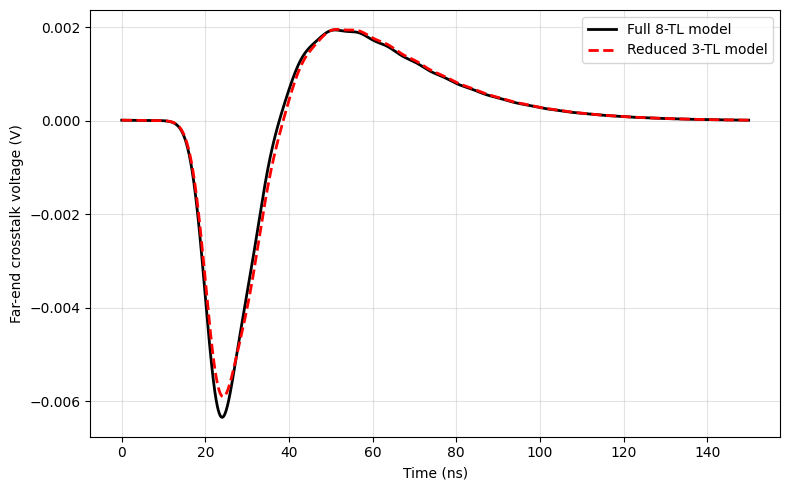

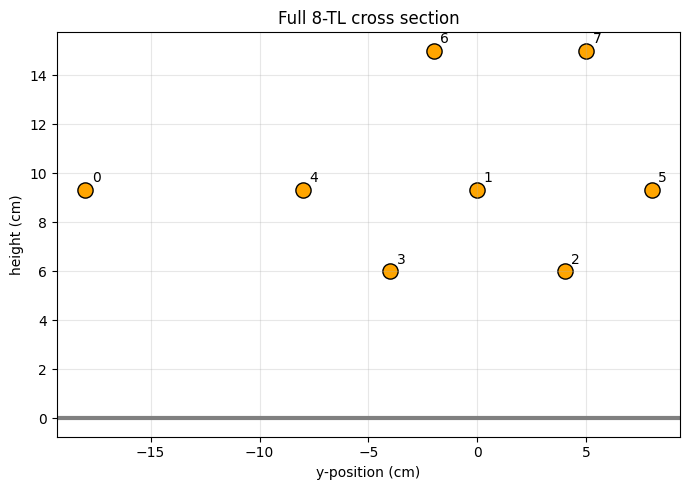

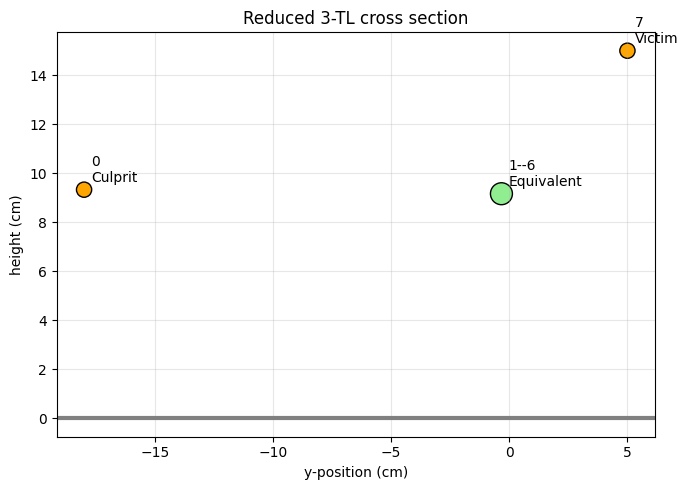

In [1]:
# Código 2
# O Código 2 implementa uma técnica de redução de modelo MTL. Ele parte de um sistema com 8 condutores
# e substitui os condutores intermediários por um condutor equivalente, reduzindo o problema para 3 condutores.
# Em seguida, compara a resposta de crosstalk do modelo completo e do modelo reduzido no domínio do tempo.
# NEXT e FEXT são tipos de crosstalk, ou seja, interferência eletromagnética entre linhas/cabos próximos.
    # - NEXT = Near-End Crosstalk (É a interferência medida no mesmo lado da fonte).
    # - FEXT = Far-End Crosstalk (É a interferência medida no lado oposto da fonte, no fim da linha).
# O MTL significa Multiconductor Transmission Line, ou Linha de Transmissão Multicondutora.
# Implementa o modelo MTL clássico.
# Constrói as matrizes L e C.
# Resolve as equações MTL usando a matriz de propagação.
# Calcula NEXT e FEXT para um sistema de 8 condutores e para um modelo reduzido de 3 condutores.




import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm
import pandas as pd

# ============================================================
# CÓDIGO 2 — Modelo MTL completo vs modelo reduzido
# Baseado em redução 8-TL -> 3-TL
# ============================================================

eps0 = 8.854187817e-12
mu0 = 4*np.pi*1e-7
c0 = 1/np.sqrt(mu0*eps0)

# ------------------------------------------------------------
# 1. Parâmetros físicos
# ------------------------------------------------------------

L_line = 1.0              # comprimento da linha (m)
r = 0.03e-2               # raio dos condutores: 0.03 cm = 0.0003 m
eps_r = 1.0               # ar

# Tempo
Tmax = 150e-9
Nt = 2048
dt = Tmax/Nt
t = np.arange(Nt)*dt

freq = np.fft.rfftfreq(Nt, dt)
omega = 2*np.pi*freq

# Pulso de excitação
t0 = 20e-9
tau = 5e-9
vs_t = np.exp(-((t-t0)/tau)**2)
Vs_f = np.fft.rfft(vs_t)

# ------------------------------------------------------------
# 2. Geometria aproximada do modelo de 8 condutores
#    Unidades em metro
# ------------------------------------------------------------

# Condutores: 0 = culprit, 7 = victim, 1-6 = intermediários
positions_8 = {
    0: (-0.18, 0.0933),
    1: ( 0.00, 0.0933),
    2: ( 0.04, 0.0600),
    3: (-0.04, 0.0600),
    4: (-0.08, 0.0933),
    5: ( 0.08, 0.0933),
    6: (-0.02, 0.1500),
    7: ( 0.05, 0.1500),
}

order_8 = [0,1,2,3,4,5,6,7]
x8 = np.array([positions_8[i][0] for i in order_8])
h8 = np.array([positions_8[i][1] for i in order_8])
r8 = np.ones(8)*r

# ------------------------------------------------------------
# 3. Cargas terminais conforme tabela do artigo
# ------------------------------------------------------------

R_near_8 = np.array([50,100,150,200,250,300,350,50], dtype=float)
R_far_8  = np.array([50,100,150,200,250,300,350,50], dtype=float)

# Fonte no condutor 0
source_index_8 = 0
victim_index_8 = 7

# ------------------------------------------------------------
# 4. Matrizes p.u.l. para fios acima de plano de terra PEC
# ------------------------------------------------------------

def build_potential_matrix(x, h, radii, eps_r=1.0):
    n = len(x)
    eps = eps0*eps_r
    P = np.zeros((n,n))

    for i in range(n):
        for j in range(n):
            if i == j:
                P[i,j] = (1/(2*np.pi*eps))*np.log(2*h[i]/radii[i])
            else:
                dij = np.sqrt((x[i]-x[j])**2 + (h[i]-h[j])**2)
                dij_img = np.sqrt((x[i]-x[j])**2 + (h[i]+h[j])**2)
                P[i,j] = (1/(2*np.pi*eps))*np.log(dij_img/dij)

    return P

def build_LC_matrices(x, h, radii, eps_r=1.0):
    P = build_potential_matrix(x, h, radii, eps_r)
    C = np.linalg.inv(P)
    L = mu0*eps0*eps_r*P
    return L, C

# ------------------------------------------------------------
# 5. Redução dos condutores intermediários 1-6
# ------------------------------------------------------------

def parallel_resistance(R):
    return 1/np.sum(1/np.array(R))

def reduce_middle_group(x, h, radii, Lmat, R_near, R_far):
    # grupo intermediário: condutores 1 a 6
    middle_ids = [1,2,3,4,5,6]

    x_mid = x[middle_ids]
    h_mid = h[middle_ids]
    Rn_mid = R_near[middle_ids]
    Rf_mid = R_far[middle_ids]

    L_mid = Lmat[np.ix_(middle_ids, middle_ids)]

    B = np.linalg.inv(L_mid)
    L_eq = 1/np.sum(B)

    h_eq = np.mean(h_mid)
    x_eq = np.mean(x_mid)

    r_eq = 2*h_eq/np.exp(2*np.pi*L_eq/mu0)

    Rn_eq = parallel_resistance(Rn_mid)
    Rf_eq = parallel_resistance(Rf_mid)

    return x_eq, h_eq, r_eq, Rn_eq, Rf_eq, L_eq

# ------------------------------------------------------------
# 6. Solução MTL no domínio da frequência
# ------------------------------------------------------------

def solve_mtl_frequency(Lmat, Cmat, R_near, R_far, source_index, Vs_complex, freq_value):
    n = len(R_near)

    if freq_value == 0:
        freq_value = 1.0

    w = 2*np.pi*freq_value

    Z = 1j*w*Lmat
    Y = 1j*w*Cmat

    A = np.block([
        [np.zeros((n,n)), -Z],
        [-Y, np.zeros((n,n))]
    ])

    Phi = expm(A*L_line)

    Phi11 = Phi[:n,:n]
    Phi12 = Phi[:n,n:]
    Phi21 = Phi[n:,:n]
    Phi22 = Phi[n:,n:]

    Rs = np.diag(R_near)
    Rl = np.diag(R_far)

    Vs = np.zeros(n, dtype=complex)
    Vs[source_index] = Vs_complex

    # Condição na entrada: V0 = Vs - Rs I0
    # Condição na saída:  VL = Rl IL
    # [VL; IL] = Phi [V0; I0]
    # resolver para I0
    M = Phi11 @ (-Rs) + Phi12 - Rl @ (Phi21 @ (-Rs) + Phi22)
    b = -Phi11 @ Vs + Rl @ Phi21 @ Vs

    I0 = np.linalg.solve(M, b)
    V0 = Vs - Rs @ I0

    VL = Phi11 @ V0 + Phi12 @ I0
    IL = Phi21 @ V0 + Phi22 @ I0

    return V0, I0, VL, IL

def simulate_time_response(x, h, radii, R_near, R_far, source_index, victim_index):
    Lmat, Cmat = build_LC_matrices(x, h, radii, eps_r)

    V_near_f = np.zeros_like(Vs_f, dtype=complex)
    V_far_f  = np.zeros_like(Vs_f, dtype=complex)

    for k, fk in enumerate(freq):
        V0, I0, VL, IL = solve_mtl_frequency(
            Lmat, Cmat, R_near, R_far,
            source_index, Vs_f[k], fk
        )

        V_near_f[k] = V0[victim_index]
        V_far_f[k]  = VL[victim_index]

    v_near_t = np.fft.irfft(V_near_f, n=Nt)
    v_far_t  = np.fft.irfft(V_far_f, n=Nt)

    return v_near_t, v_far_t, Lmat, Cmat

# ------------------------------------------------------------
# 7. Modelo completo de 8 condutores
# ------------------------------------------------------------

v_near_8, v_far_8, L8, C8 = simulate_time_response(
    x8, h8, r8,
    R_near_8, R_far_8,
    source_index_8, victim_index_8
)

# ------------------------------------------------------------
# 8. Modelo reduzido 3 condutores
#    [0, equivalente(1-6), 7]
# ------------------------------------------------------------

x_eq, h_eq, r_eq, Rn_eq, Rf_eq, L_eq = reduce_middle_group(
    x8, h8, r8, L8, R_near_8, R_far_8
)

x3 = np.array([x8[0], x_eq, x8[7]])
h3 = np.array([h8[0], h_eq, h8[7]])
r3 = np.array([r8[0], r_eq, r8[7]])

R_near_3 = np.array([R_near_8[0], Rn_eq, R_near_8[7]])
R_far_3  = np.array([R_far_8[0],  Rf_eq, R_far_8[7]])

source_index_3 = 0
victim_index_3 = 2

v_near_3, v_far_3, L3, C3 = simulate_time_response(
    x3, h3, r3,
    R_near_3, R_far_3,
    source_index_3, victim_index_3
)

# ------------------------------------------------------------
# 9. Métricas de erro
# ------------------------------------------------------------

def error_metrics_time(model, ref):
    err = model - ref
    mae = np.mean(np.abs(err))
    rmse = np.sqrt(np.mean(err**2))
    maxe = np.max(np.abs(err))
    return mae, rmse, maxe

metrics = {
    "Near-end: Reduced vs Full": error_metrics_time(v_near_3, v_near_8),
    "Far-end: Reduced vs Full": error_metrics_time(v_far_3, v_far_8),
}

df = pd.DataFrame(
    metrics,
    index=["MAE (V)", "RMSE (V)", "MAX error (V)"]
).T

print("\nEquivalent parameters:")
print(f"h_eq  = {h_eq*100:.2f} cm")
print(f"r_eq  = {r_eq*100:.2f} cm")
print(f"Rn_eq = {Rn_eq:.2f} ohm")
print(f"Rf_eq = {Rf_eq:.2f} ohm")
print(f"L_eq  = {L_eq:.3e} H/m")

print("\nError metrics:")
print(df)

# ------------------------------------------------------------
# 10. Figuras comparativas
# ------------------------------------------------------------

plt.figure(figsize=(8,5))
plt.plot(t*1e9, v_near_8, color="black", linewidth=2.0, label="Full 8-TL model")
plt.plot(t*1e9, v_near_3, "--", color="red", linewidth=2.0, label="Reduced 3-TL model")
plt.xlabel("Time (ns)")
plt.ylabel("Near-end crosstalk voltage (V)")
plt.grid(True, alpha=0.35)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(8,5))
plt.plot(t*1e9, v_far_8, color="black", linewidth=2.0, label="Full 8-TL model")
plt.plot(t*1e9, v_far_3, "--", color="red", linewidth=2.0, label="Reduced 3-TL model")
plt.xlabel("Time (ns)")
plt.ylabel("Far-end crosstalk voltage (V)")
plt.grid(True, alpha=0.35)
plt.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 11. Geometria completa e reduzida
# ------------------------------------------------------------

plt.figure(figsize=(7,5))
plt.scatter(x8*100, h8*100, s=120, color="orange", edgecolor="black")

for i, idx in enumerate(order_8):
    plt.text(x8[i]*100+0.3, h8[i]*100+0.3, str(idx), fontsize=10)

plt.axhline(0, color="gray", linewidth=3)
plt.xlabel("y-position (cm)")
plt.ylabel("height (cm)")
plt.title("Full 8-TL cross section")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(7,5))
plt.scatter(x3*100, h3*100, s=[120,250,120],
            color=["orange","lightgreen","orange"], edgecolor="black")

labels = ["0\nCulprit", "1--6\nEquivalent", "7\nVictim"]
for i, lab in enumerate(labels):
    plt.text(x3[i]*100+0.3, h3[i]*100+0.3, lab, fontsize=10)

plt.axhline(0, color="gray", linewidth=3)
plt.xlabel("y-position (cm)")
plt.ylabel("height (cm)")
plt.title("Reduced 3-TL cross section")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()